# Zero-Trust Database Access & Exfiltration Sentinel
### Inspired by the FBI NCIC & USDA breach reports

**Problem:** once a credential or API endpoint to a high-value database is compromised, attackers quietly bulk-query records before anyone notices, and often wipe the audit logs afterwards.

**What this notebook builds**

| # | Component | Purpose |
|---|-----------|---------|
| 1 | Synthetic operator query-log generator | Realistic normal behaviour + injected exfiltration attacks (real NCIC logs are not public) |
| 2 | Behavioral Query Anomaly Engine | Isolation Forest + NumPy autoencoder ensemble |
| 3 | Tamper-Proof Forensic Ledger | SHA-256 hash chain + Merkle tree + signed checkpoints + inclusion proofs |
| 4 | Sentinel SQL proxy (SQLite) | Intercepts `SELECT`/`EXPORT`, scores the session, **ALLOW / THROTTLE / FREEZE**, logs to ledger |
| 5 | Attack simulation + tamper demo | End-to-end proof that it works |
| 6 | (Optional) Government open-data fetcher | Pull real datasets from data.gov to use as protected tables |

**Stack:** Python, NumPy, scikit-learn, SQLite, hashlib/hmac (FastAPI wiring sketched at the end).

In [1]:
import hashlib, hmac, json, sqlite3, time, datetime as dt
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

rng = np.random.default_rng(42)
print("ready")

ready


## 1. Synthetic operator behaviour

Each row = one **operator-hour window**. Features capture the signals named in the design: query velocity, off-hours access, subnet drift, and record-volume spikes (+ export count and table breadth).

- **Normal:** operators work their own shift, from their home subnet, with modest result sizes.
- **Attack (label = 1):** a stolen credential used from a new subnet, often at night, with many queries, huge row counts and exports.

In [2]:
N_OPS, N_DAYS = 60, 30

def make_operators(n):
    ops = []
    for i in range(n):
        start = int(rng.integers(6, 11))
        ops.append(dict(
            op=f"op{i:03d}", shift=(start, start + 9),
            rate=float(rng.uniform(4, 18)),            # queries / active hour
            rows_mu=float(rng.uniform(1.5, 3.5)),      # log-mean of rows per query
            subnet=int(rng.integers(1, 40)),
        ))
    return ops

OPS = make_operators(N_OPS)

def gen_window(o, day, hour, attack=False):
    if not attack:
        q = max(1, rng.poisson(o["rate"]))
        rpq = rng.lognormal(o["rows_mu"], 0.7, q)
        rows = int(rpq.sum())
        exports = int(rng.random() < 0.03) * int(rng.integers(1, 3))
        offh = 0.0 if o["shift"][0] <= hour < o["shift"][1] else 1.0
        drift = int(rng.random() < 0.01)               # occasional VPN/travel
        tables = int(rng.integers(1, 4))
    else:
        q = int(rng.integers(60, 400))
        rows = int(q * rng.lognormal(5.0, 0.6))
        exports = int(rng.integers(0, 12))
        offh = float(rng.choice([0.0, 0.6, 1.0], p=[0.25, 0.25, 0.5]))
        drift = int(rng.random() < 0.85)
        tables = int(rng.integers(3, 9))
    return dict(operator=o["op"], day=day, hour=hour, query_count=q, rows_total=rows,
                export_count=exports, offhours_frac=offh, subnet_drift=drift,
                distinct_tables=tables, label=int(attack))

def build_log(day_range, attack_rate):
    out = []
    for d in day_range:
        for o in OPS:
            for h in range(24):
                in_shift = o["shift"][0] <= h < o["shift"][1]
                if in_shift and rng.random() < 0.9:
                    out.append(gen_window(o, d, h))
                elif (not in_shift) and rng.random() < 0.01:   # rare legit on-call
                    out.append(gen_window(o, d, h))
                if rng.random() < attack_rate:
                    out.append(gen_window(o, d, h, attack=True))
    return pd.DataFrame(out)

train_df = build_log(range(0, 20), attack_rate=0.0003)   # ~clean, tiny contamination (unsupervised)
test_df  = build_log(range(20, 30), attack_rate=0.002)
print(train_df.shape, test_df.shape, "| train attacks:", train_df.label.sum(), "| test attacks:", test_df.label.sum())
train_df.head()

(9879, 10) (4991, 10) | train attacks: 6 | test attacks: 20


,operator,day,hour,query_count,rows_total,export_count,offhours_frac,subnet_drift,distinct_tables,label
0,op000,0,6,14,412,0,0.0,0,2,0
1,op000,0,7,13,372,0,0.0,0,2,0
2,op000,0,8,13,319,0,0.0,0,3,0
3,op000,0,9,8,199,0,0.0,0,2,0
4,op000,0,10,10,398,0,0.0,0,1,0


## 2. Behavioral Query Anomaly Engine

Two unsupervised detectors trained **without labels** on normal operator behaviour:

1. **Isolation Forest** - good at isolating extreme volume spikes.
2. **NumPy autoencoder** - learns the manifold of normal feature combinations; reconstruction error flags unusual *combinations* (e.g. low volume but new subnet at 3 a.m.).

Scores are converted to percentile ranks against the training distribution and averaged.

In [3]:
FEATURES = ["f_queries", "f_rows", "f_exports", "f_offhours", "f_drift", "f_tables", "f_rpq"]

def featurize(query_count, rows_total, export_count, offhours_frac, subnet_drift, distinct_tables):
    # shared by offline training AND the live proxy, so the two never diverge
    q = np.asarray(query_count, float)
    r = np.asarray(rows_total, float)
    return np.column_stack([
        np.log1p(q), np.log1p(r), np.log1p(export_count), offhours_frac,
        subnet_drift, np.asarray(distinct_tables, float), np.log1p(r / np.maximum(q, 1)),
    ])

def df_to_X(df):
    return featurize(df.query_count, df.rows_total, df.export_count,
                     df.offhours_frac, df.subnet_drift, df.distinct_tables)

class NumpyAutoencoder:
    def __init__(self, d_in, hidden=(5, 2), lr=3e-3, seed=0):
        r = np.random.default_rng(seed)
        sizes = [d_in, *hidden, *hidden[-2::-1], d_in]
        self.W = [r.normal(0, np.sqrt(2 / sizes[i]), (sizes[i], sizes[i + 1])) for i in range(len(sizes) - 1)]
        self.b = [np.zeros(sizes[i + 1]) for i in range(len(sizes) - 1)]
        self.lr = lr
        self.m = [np.zeros_like(w) for w in self.W] + [np.zeros_like(b) for b in self.b]
        self.v = [np.zeros_like(w) for w in self.W] + [np.zeros_like(b) for b in self.b]
        self.t = 0

    def _fwd(self, X):
        acts = [X]
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            z = acts[-1] @ W + b
            acts.append(z if i == len(self.W) - 1 else np.tanh(z))
        return acts

    def fit(self, X, epochs=60, batch=256):
        n = len(X)
        for ep in range(epochs):
            idx = rng.permutation(n)
            for s in range(0, n, batch):
                xb = X[idx[s:s + batch]]
                acts = self._fwd(xb)
                grad = 2 * (acts[-1] - xb) / len(xb)
                gW, gb = [], []
                for i in reversed(range(len(self.W))):
                    gW.insert(0, acts[i].T @ grad)
                    gb.insert(0, grad.sum(0))
                    if i > 0:
                        grad = (grad @ self.W[i].T) * (1 - acts[i] ** 2)
                self._adam(gW + gb)
        return self

    def _adam(self, grads, b1=0.9, b2=0.999, eps=1e-8):
        self.t += 1
        params = self.W + self.b
        for i, (p, g) in enumerate(zip(params, grads)):
            self.m[i] = b1 * self.m[i] + (1 - b1) * g
            self.v[i] = b2 * self.v[i] + (1 - b2) * g * g
            mh = self.m[i] / (1 - b1 ** self.t); vh = self.v[i] / (1 - b2 ** self.t)
            p -= self.lr * mh / (np.sqrt(vh) + eps)

    def score(self, X):
        return ((self._fwd(X)[-1] - X) ** 2).mean(1)


class BehaviorEngine:
    def __init__(self):
        self.scaler = StandardScaler()
        self.iso = IsolationForest(n_estimators=300, contamination="auto", random_state=7)
        self.ae = NumpyAutoencoder(len(FEATURES), seed=1)

    def fit(self, X):
        Xs = self.scaler.fit_transform(X)
        self.iso.fit(Xs)
        self.ae.fit(Xs)
        self.ref_iso = np.sort(-self.iso.score_samples(Xs))
        self.ref_ae = np.sort(self.ae.score(Xs))
        return self

    def risk(self, X):
        # 0..1 risk = mean percentile of the two detectors vs. the normal training distribution
        Xs = self.scaler.transform(X)
        r1 = np.searchsorted(self.ref_iso, -self.iso.score_samples(Xs)) / len(self.ref_iso)
        r2 = np.searchsorted(self.ref_ae, self.ae.score(Xs)) / len(self.ref_ae)
        return (r1 + r2) / 2

engine = BehaviorEngine().fit(df_to_X(train_df))
print("engine trained")

engine trained


ROC-AUC: 1.0
NOTE: synthetic attacks are deliberately extreme, so near-perfect AUC is expected. Real attackers who stay
      low-and-slow will score lower; validate on real (anonymised) logs before trusting these numbers.
action  ALLOW  FREEZE  THROTTLE
label                          
attack      0      16         4
normal   4961       0        10
              precision    recall  f1-score   support

      normal      1.000     0.998     0.999      4971
      attack      0.667     1.000     0.800        20

    accuracy                          0.998      4991
   macro avg      0.833     0.999     0.899      4991
weighted avg      0.999     0.998     0.998      4991



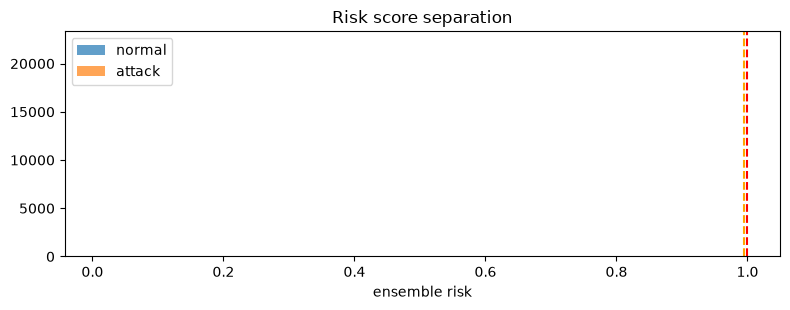

In [4]:
test_df["risk"] = engine.risk(df_to_X(test_df))
print("ROC-AUC:", round(roc_auc_score(test_df.label, test_df.risk), 4))
print("NOTE: synthetic attacks are deliberately extreme, so near-perfect AUC is expected. Real attackers who stay\n"
      "      low-and-slow will score lower; validate on real (anonymised) logs before trusting these numbers.")

THROTTLE_AT, FREEZE_AT = 0.995, 0.9995
def decide(risk):
    return "FREEZE" if risk >= FREEZE_AT else "THROTTLE" if risk >= THROTTLE_AT else "ALLOW"

test_df["action"] = test_df.risk.map(decide)
print(pd.crosstab(test_df.label.map({0: "normal", 1: "attack"}), test_df.action))

flagged = (test_df.action != "ALLOW").astype(int)
print(classification_report(test_df.label, flagged, target_names=["normal", "attack"], digits=3))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(test_df.risk[test_df.label == 0], bins=60, alpha=.7, label="normal", density=True)
ax.hist(test_df.risk[test_df.label == 1], bins=60, alpha=.7, label="attack", density=True)
ax.axvline(THROTTLE_AT, ls="--", c="orange"); ax.axvline(FREEZE_AT, ls="--", c="red")
ax.set_xlabel("ensemble risk"); ax.legend(); ax.set_title("Risk score separation"); plt.tight_layout(); plt.show()

## 3. Tamper-Proof Forensic Ledger

Every `SELECT` / `EXPORT` on a sensitive table becomes a ledger entry that is:

- **hash-chained** (`prev_hash` -> `entry_hash`), so editing or deleting any entry breaks every later hash;
- a **leaf of a Merkle tree**, so a single entry can be proven to be in the log with an O(log n) **inclusion proof**;
- covered by **signed checkpoints** (`HMAC-SHA256` over `size || merkle_root`). Ship checkpoints to external WORM storage so an attacker who owns the DB host can't rewrite history silently.

> Production note: replace the HMAC with an asymmetric signature (Ed25519) held in an HSM/KMS so verifiers don't need the secret.

In [5]:
def sha(b: bytes) -> bytes: return hashlib.sha256(b).digest()
LEAF, NODE = b"\x00", b"\x01"   # domain separation prevents second-preimage attacks on the tree

def merkle_root(leaves):
    if not leaves: return sha(b"")
    level = list(leaves)
    while len(level) > 1:
        if len(level) % 2: level.append(level[-1])
        level = [sha(NODE + level[i] + level[i + 1]) for i in range(0, len(level), 2)]
    return level[0]

def merkle_proof(leaves, idx):
    proof, level = [], list(leaves)
    while len(level) > 1:
        if len(level) % 2: level.append(level[-1])
        sib = idx ^ 1
        proof.append(("L" if sib < idx else "R", level[sib].hex()))
        level = [sha(NODE + level[i] + level[i + 1]) for i in range(0, len(level), 2)]
        idx //= 2
    return proof

def verify_proof(leaf, proof, root):
    h = leaf
    for side, sib in proof:
        sib = bytes.fromhex(sib)
        h = sha(NODE + sib + h) if side == "L" else sha(NODE + h + sib)
    return h == root

class AuditLedger:
    GENESIS = "0" * 64
    def __init__(self, signing_key: bytes):
        self.key, self.entries, self.checkpoints = signing_key, [], []

    @staticmethod
    def _body(e): return json.dumps({k: e[k] for k in ("seq", "ts", "event", "prev_hash")}, sort_keys=True).encode()

    def append(self, event: dict):
        prev = self.entries[-1]["entry_hash"] if self.entries else self.GENESIS
        e = dict(seq=len(self.entries), ts=event.get("ts", time.time()), event=event, prev_hash=prev)
        e["entry_hash"] = sha(self._body(e)).hex()
        self.entries.append(e)
        return e

    def _leaves(self): return [sha(LEAF + bytes.fromhex(e["entry_hash"])) for e in self.entries]
    def root(self): return merkle_root(self._leaves())

    def checkpoint(self):
        root = self.root(); size = len(self.entries)
        sig = hmac.new(self.key, size.to_bytes(8, "big") + root, hashlib.sha256).hexdigest()
        cp = dict(size=size, root=root.hex(), sig=sig); self.checkpoints.append(cp); return cp

    def prove(self, seq): return merkle_proof(self._leaves(), seq)

    def verify(self):
        # returns (ok, reason). Checks chain, every entry hash, and all signed checkpoints.
        prev = self.GENESIS
        for e in self.entries:
            if e["prev_hash"] != prev: return False, f"chain broken at seq {e['seq']}"
            if sha(self._body(e)).hex() != e["entry_hash"]: return False, f"entry {e['seq']} modified"
            prev = e["entry_hash"]
        for cp in self.checkpoints:
            root = merkle_root(self._leaves()[:cp["size"]])
            exp = hmac.new(self.key, cp["size"].to_bytes(8, "big") + root, hashlib.sha256).hexdigest()
            if root.hex() != cp["root"] or not hmac.compare_digest(exp, cp["sig"]):
                return False, f"checkpoint (size={cp['size']}) mismatch"
        return True, "ledger intact"

# quick self-test
L = AuditLedger(b"demo-key")
for i in range(7): L.append({"op": f"op{i}", "sql": "SELECT 1"})
cp = L.checkpoint()
p = L.prove(3)
print(L.verify(), "| proof ok:", verify_proof(L._leaves()[3], p, L.root()))

(True, 'ledger intact') | proof ok: True


## 4. The Sentinel proxy

A thin proxy in front of SQLite. For each statement it:

1. Updates the session's rolling 1-hour window (queries, rows, exports, tables, off-hours, subnet drift).
2. Scores the window with the **same** `featurize()` + `engine` used offline.
3. Enforces **ALLOW / THROTTLE (row cap) / FREEZE (session killed)**.
4. Writes the decision and a hash of the SQL into the Merkle ledger **before returning data**.

Simulated time is passed in so we can replay a 3 a.m. attack deterministically.

In [6]:
SENSITIVE = {"citizens", "warrants"}
THROTTLE_ROW_CAP = 25

class SessionFrozen(Exception): pass

class Session:
    def __init__(self, operator, home_subnet, shift):
        self.operator, self.home_subnet, self.shift = operator, home_subnet, shift
        self.events = deque()      # (ts, rows, is_export, table, offhours, drifted)
        self.frozen = False

class Sentinel:
    WINDOW = 3600
    def __init__(self, conn, engine, ledger):
        self.conn, self.engine, self.ledger = conn, engine, ledger

    def _features(self, s, now):
        while s.events and now - s.events[0][0] > self.WINDOW: s.events.popleft()
        ev = list(s.events)
        if not ev: return None
        q = len(ev)
        return featurize([q], [sum(e[1] for e in ev)], [sum(e[2] for e in ev)],
                         [np.mean([e[4] for e in ev])], [int(any(e[5] for e in ev))],
                         [len({e[3] for e in ev})])

    def execute(self, s, sql, params=(), *, now, src_subnet, export=False):
        if s.frozen:
            self.ledger.append(dict(ts=now, operator=s.operator, action="DENIED_FROZEN", sql_sha=sha(sql.encode()).hex()))
            raise SessionFrozen(f"{s.operator}: session frozen, contact SOC")
        low = sql.lower()
        table = next((t for t in SENSITIVE if t in low), "other")
        hour = dt.datetime.fromtimestamp(now, dt.timezone.utc).hour
        offh = float(not (s.shift[0] <= hour < s.shift[1]))
        drift = src_subnet != s.home_subnet

        cur = self.conn.execute(sql, params)
        rows = cur.fetchall()
        s.events.append((now, len(rows), int(export), table, offh, drift))

        risk = float(self.engine.risk(self._features(s, now))[0])
        action = decide(risk)
        if action == "FREEZE":
            s.frozen, rows = True, []
        elif action == "THROTTLE":
            rows = rows[:THROTTLE_ROW_CAP]

        if table in SENSITIVE or action != "ALLOW":
            self.ledger.append(dict(ts=now, operator=s.operator, verb="EXPORT" if export else "SELECT",
                                    table=table, rows_returned=len(rows), src_subnet=src_subnet,
                                    risk=round(risk, 5), action=action, sql_sha=sha(sql.encode()).hex()))
        return rows, action, risk

# --- demo protected database (swap in real open data in section 6) ---
conn = sqlite3.connect(":memory:")
conn.execute("CREATE TABLE citizens (id INTEGER PRIMARY KEY, name TEXT, agency TEXT, record_type TEXT)")
agencies = ["TX-DPS", "CA-LAPD", "NY-NYPD", "FL-FDLE", "IL-ISP"]
conn.executemany("INSERT INTO citizens VALUES (?,?,?,?)",
                 [(i, f"Person {i}", agencies[i % 5], ["warrant", "vehicle", "gang", "missing"][i % 4]) for i in range(20000)])
conn.commit()

ledger = AuditLedger(signing_key=b"replace-with-kms-secret")
sentinel = Sentinel(conn, engine, ledger)
print("proxy ready; rows:", conn.execute("select count(*) from citizens").fetchone()[0])

proxy ready; rows: 20000


## 5. Simulation: legitimate operator vs. compromised credential

In [7]:
base = dt.datetime(2026, 11, 20, tzinfo=dt.timezone.utc)
ts = lambda h, m=0, s=0: (base + dt.timedelta(hours=h, minutes=m, seconds=s)).timestamp()

# Legit operator: day shift, home subnet, small lookups
alice = Session("alice", home_subnet=12, shift=(8, 17))
log = []
for i in range(14):
    rows, act, risk = sentinel.execute(alice, "SELECT * FROM citizens WHERE id = ?", (int(rng.integers(0, 20000)),),
                                       now=ts(10, i * 3), src_subnet=12)
    log.append(("alice", i, len(rows), act, round(risk, 4)))
print("Alice (normal):", pd.Series([l[3] for l in log]).value_counts().to_dict())

# Attacker: stolen alice-like credential, 03:12 UTC, unknown subnet, bulk scraping + exports
mallory = Session("mallory", home_subnet=12, shift=(8, 17))
atk = []
try:
    for i in range(400):
        lim = min(800, 15 + i * 12)                      # attacker starts quiet, then ramps up
        rows, act, risk = sentinel.execute(
            mallory, f"SELECT * FROM citizens WHERE id >= ? LIMIT {lim}", (i * 50,),
            now=ts(3, 12, i * 6), src_subnet=203, export=(i > 8 and i % 3 == 0))
        atk.append((i, len(rows), act, round(risk, 4)))
except SessionFrozen as e:
    print("BLOCKED ->", e)

a = pd.DataFrame(atk, columns=["query_no", "rows_returned", "action", "risk"])
first = lambda x: a[a.action == x].query_no.min() if (a.action == x).any() else None
print(f"Attack: first THROTTLE at query #{first('THROTTLE')}, first FREEZE at query #{first('FREEZE')}")
unprotected = sum(min(800, 15 + i * 12) for i in range(400))
print(f"Rows actually leaked: {a.rows_returned.sum():,} of {unprotected:,} the attacker would have pulled unprotected "
      f"({100 * a.rows_returned.sum() / unprotected:.1f}%)")
a.tail(3)

Alice (normal): {'ALLOW': 14}
BLOCKED -> mallory: session frozen, contact SOC
Attack: first THROTTLE at query #0, first FREEZE at query #12
Rows actually leaked: 626 of 293,930 the attacker would have pulled unprotected (0.2%)


,query_no,rows_returned,action,risk
10,10,25,THROTTLE,0.9993
11,11,25,THROTTLE,0.9993
12,12,0,FREEZE,0.9995


In [8]:
# post-freeze: any further attempt is denied AND logged
try: sentinel.execute(mallory, "SELECT * FROM citizens", now=ts(3, 40), src_subnet=203)
except SessionFrozen as e: print("denied:", e)

ledger.checkpoint()
print("ledger entries:", len(ledger.entries), "| verify:", ledger.verify())
pd.DataFrame([{**{k: v for k, v in e["event"].items() if k != "sql_sha"}, "seq": e["seq"]} for e in ledger.entries[-6:]])

denied: mallory: session frozen, contact SOC
ledger entries: 29 | verify: (True, 'ledger intact')


,ts,operator,verb,table,rows_returned,src_subnet,risk,action,seq
0,1.795144e+09,mallory,EXPORT,citizens,25.0,203.0,0.99934,THROTTLE,23
1,1.795144e+09,mallory,SELECT,citizens,25.0,203.0,0.99934,THROTTLE,24
2,1.795144e+09,mallory,SELECT,citizens,25.0,203.0,0.99934,THROTTLE,25
3,1.795144e+09,mallory,EXPORT,citizens,0.0,203.0,0.99954,FREEZE,26
4,1.795144e+09,mallory,NaN,NaN,NaN,NaN,NaN,DENIED_FROZEN,27
5,1.795146e+09,mallory,NaN,NaN,NaN,NaN,NaN,DENIED_FROZEN,28


### Tamper test: attacker tries to wipe their tracks

We simulate an attacker with DB-level access who (a) edits an incriminating entry, then (b) deletes it. Both are detected, and the Merkle inclusion proof lets an auditor verify any surviving entry against the externally stored signed checkpoint.

In [9]:
import copy
trusted_cp = copy.deepcopy(ledger.checkpoints[-1])      # imagine this was shipped to WORM storage

# an inclusion proof for a specific forensic record
idx = next(e["seq"] for e in ledger.entries if e["event"].get("action") == "FREEZE")
proof = ledger.prove(idx)
print("proof for FREEZE entry verifies against root:", verify_proof(ledger._leaves()[idx], proof, bytes.fromhex(trusted_cp["root"])) if idx < trusted_cp["size"] else "n/a")

# (a) modify an entry
tampered = copy.deepcopy(ledger)
tampered.entries[idx]["event"]["action"] = "ALLOW"
print("after EDIT  :", tampered.verify())

# (b) delete the entry
deleted = copy.deepcopy(ledger)
del deleted.entries[idx]
print("after DELETE:", deleted.verify())

# (c) attacker recomputes the whole chain to hide it -> root no longer matches the external checkpoint
rewritten = AuditLedger(b"attacker-doesnt-know-the-key")
for e in ledger.entries:
    ev = copy.deepcopy(e["event"])
    if e["seq"] == idx: ev["action"] = "ALLOW"
    rewritten.append(ev)
print("rewritten chain internally consistent:", rewritten.verify()[0],
      "| matches trusted checkpoint root:", rewritten.root().hex() == trusted_cp["root"])

proof for FREEZE entry verifies against root: True
after EDIT  : (False, 'entry 26 modified')
after DELETE: (False, 'chain broken at seq 27')
rewritten chain internally consistent: True | matches trusted checkpoint root: False


## 6. (Optional) Use real government open data

The real NCIC is not public, but data.gov exposes thousands of open datasets through a CKAN API. The helpers below search the catalog, download a CSV resource, and load it into the protected SQLite DB so the Sentinel guards real records.

> This needs internet access, so run it on your own machine. If the network call fails the cell prints a message and the rest of the notebook is unaffected. Only fetch **public open data**; respect each dataset's license and rate limits.

In [10]:
import io, urllib.parse, urllib.request

def search_datagov(query, rows=5):
    url = "https://catalog.data.gov/api/3/action/package_search?" + urllib.parse.urlencode({"q": query, "rows": rows})
    with urllib.request.urlopen(url, timeout=20) as r:
        res = json.load(r)["result"]["results"]
    out = []
    for p in res:
        for rs in p.get("resources", []):
            if (rs.get("format") or "").upper() == "CSV" and rs.get("url"):
                out.append(dict(title=p["title"], org=(p.get("organization") or {}).get("title"), csv=rs["url"]))
                break
    return pd.DataFrame(out)

def load_csv_to_sqlite(conn, url, table, max_rows=50000):
    req = urllib.request.Request(url, headers={"User-Agent": "sentinel-research/0.1"})
    with urllib.request.urlopen(req, timeout=60) as r:
        df = pd.read_csv(io.BytesIO(r.read()), nrows=max_rows, low_memory=False)
    df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]
    df.to_sql(table, conn, if_exists="replace", index=False)
    return df

try:
    found = search_datagov("law enforcement")
    display(found)
    # Example: pick the first CSV and make it a protected table
    # df = load_csv_to_sqlite(conn, found.csv.iloc[0], "warrants"); display(df.head())
except Exception as e:
    print("Skipping live fetch (offline or blocked):", type(e).__name__, e)

Skipping live fetch (offline or blocked): HTTPError HTTP Error 404: Not Found


## 7. Next steps: productionising

- **FastAPI front door:** `POST /query {session_id, sql, src_ip}` -> `Sentinel.execute(...)`; `GET /ledger/proof/{seq}`; `GET /ledger/checkpoint`.
- **Real proxy:** speak the PostgreSQL wire protocol (e.g. with `pgproxy`/PgBouncer hooks) instead of wrapping a Python connection.
- **Better features:** per-operator baselines, peer-group comparison, ASN/geo-IP, sensitivity-weighted rows, time-since-last-MFA.
- **Online learning:** periodically retrain on newly cleared traffic; keep drift monitors on the feature distributions.
- **Ledger hardening:** Ed25519 signatures with keys in an HSM, publish checkpoints to an external transparency log / WORM bucket, add consistency proofs between checkpoints.
- **Response:** wire `FREEZE` into IdP session revocation + SIEM/SOAR alerts.